<a href="https://colab.research.google.com/github/Lorenzito/ProgramacionParaAnaliticaDescriptivayPredicitva/blob/main/Pra%CC%81cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [1]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Lectura del conjunto de datos: solo se eligen las columnas que pide la práctica
# salary (dependiente), cost (independiente numérica) y location (independiente categórica)
df = pd.read_csv('college.csv', usecols=['salary', 'cost', 'location'])

# Información general para revisar los tipos de dato de cada columna
print('Información general del conjunto de datos\n')
print(df.info())

Información general del conjunto de datos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   salary    85 non-null     int64 
 1   cost      85 non-null     int64 
 2   location  85 non-null     object
dtypes: int64(2), object(1)
memory usage: 2.1+ KB
None


In [2]:
# location se leyó como texto (object); se convierte a tipo categórico
# porque representa regiones sin orden (variable nominal)
df['location'] = df['location'].astype('category')
print(df.dtypes)

salary         int64
cost           int64
location    category
dtype: object


In [3]:
# Estadística descriptiva de las dos variables numéricas: salary y cost
print('Estadística descriptiva de salary y cost\n')
print(df[['salary', 'cost']].describe())

Estadística descriptiva de salary y cost

              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000


In [4]:
# Cantidad de registros (universidades) que hay en cada categoría de location
print('Datos por categoría de location\n')
print(df['location'].value_counts())

Datos por categoría de location

location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64


In [5]:
# One-hot encoding con K-1 columnas (drop='first'): en regresión se elimina una
# categoría para evitar multicolinealidad. Se elimina la primera en orden alfabético (MW),
# que queda como categoría base (0 en todas las columnas dummy)
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoded_data = encoder.fit_transform(df[['location']])

# Se crea un DataFrame con los nombres de las nuevas columnas dummy
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(['location']))

# Se concatenan las columnas dummy al DataFrame original
df = pd.concat([df, encoded_df], axis=1)

print('Conjunto de datos con la variable location codificada\n')
print(df.head(10))

Conjunto de datos con la variable location codificada

   salary    cost location  location_NE  location_S  location_W
0  119000  189300       NE          1.0         0.0         0.0
1  121000  189600       NE          1.0         0.0         0.0
2  123000  188400       NE          1.0         0.0         0.0
3  123000  188700       NE          1.0         0.0         0.0
4  110000  194200       NE          1.0         0.0         0.0
5  112000  181900       MW          0.0         0.0         0.0
6  111000  191300       NE          1.0         0.0         0.0
7  117000  187600        S          0.0         1.0         0.0
8  111000  180400       NE          1.0         0.0         0.0
9  104000  184900       NE          1.0         0.0         0.0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




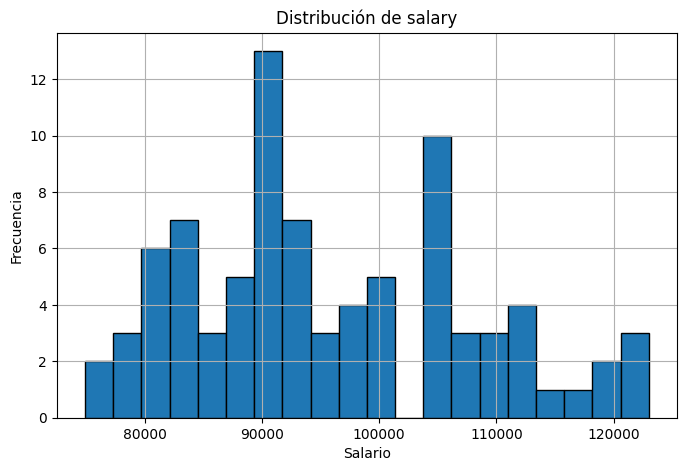

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Histograma de salary para ver cómo se distribuyen los salarios
plt.figure(figsize=(8, 5))
plt.hist(df['salary'], bins=20, edgecolor='black')
plt.title('Distribución de salary')
plt.xlabel('Salario')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.show()

**Discusión (histograma de salary):**

- Los salarios van de 74,900 a 123,000 (valores `min` y `max` del `describe()` de la sección 1). La barra más alta está cerca de 90,000, con 13 universidades, y alrededor de ella se concentra la mayor parte de los datos (aproximadamente entre 80,000 y 95,000).
- La forma no es simétrica ni de campana. Hay un segundo pico cerca de 105,000 (10 universidades) y antes de él un hueco sin observaciones, más o menos entre 101,000 y 104,000.
- Por arriba de 110,000 hay pocas universidades (barras de 1 a 4), lo que forma una cola hacia la derecha. Eso coincide con que la media (95,898.82) sea mayor que la mediana (93,200).

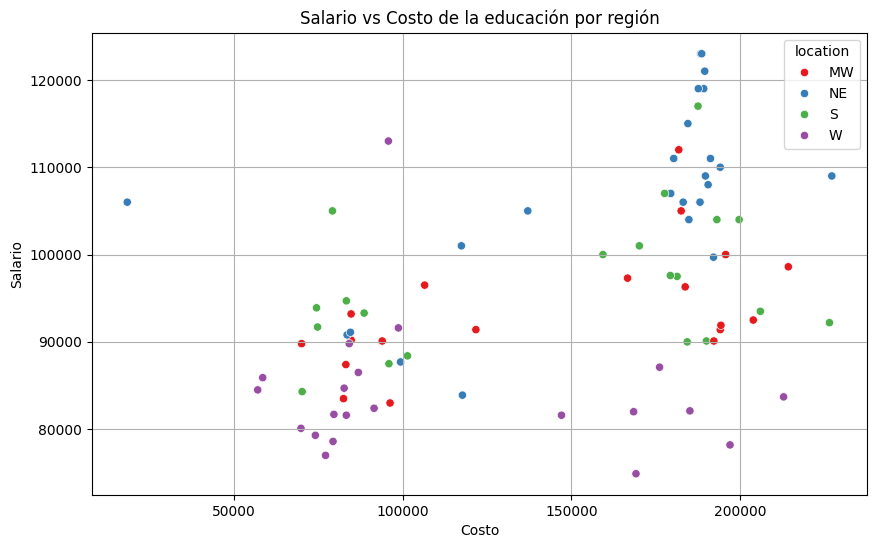

In [7]:
# Diagrama de dispersión salary vs cost; hue='location' asigna un color distinto
# a cada una de las 4 regiones para ver si la relación cambia según la localidad
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='cost', y='salary', hue='location', palette='Set1')
plt.title('Salario vs Costo de la educación por región')
plt.xlabel('Costo')
plt.ylabel('Salario')
plt.grid(True)
plt.show()

**Discusión (dispersión salary vs cost por región):**

- Los puntos forman dos grupos según el costo: uno por debajo de unos 125,000 y otro entre unos 160,000 y 227,000. Entre ambos casi no hay universidades.
- En general, cuando el costo es mayor el salario también tiende a subir, pero la relación es débil: a un mismo costo (por ejemplo, cerca de 190,000) los salarios van de unos 75,000 a 123,000.
- Lo que más ordena los salarios es el color, o sea, la región. Los puntos azules (NE) ocupan casi todos los salarios más altos (los que pasan de 115,000), mientras que los morados (W) quedan abajo, casi siempre por debajo de 92,000, sin importar si su costo es bajo o alto. Los rojos (MW) y verdes (S) se quedan en medio.
- Se ven algunos puntos alejados. El más notable es uno de NE con costo cercano a 18,000 (el mínimo de `cost` es 18,260) y salario de unos 106,000. También hay uno de W con costo cercano a 95,000 y salario de unos 113,000, muy por encima del resto de su región.

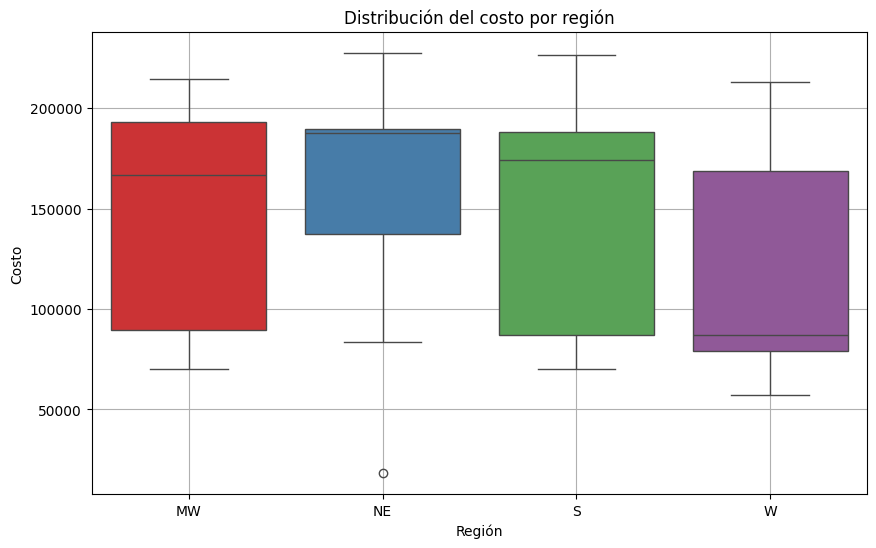

In [8]:
# Boxplot de cost por región para comparar la distribución del costo según la localidad
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='location', y='cost', hue='location', palette='Set1')
plt.title('Distribución del costo por región')
plt.xlabel('Región')
plt.ylabel('Costo')
plt.grid(True)
plt.show()

**Discusión (boxplot de cost por región):**

- Sí hay diferencias de costo entre regiones. NE tiene la mediana más alta (cerca de 188,000) y su caja es la más angosta (más o menos de 137,000 a 190,000), así que la mayoría de sus universidades son caras.
- MW y S tienen medianas parecidas entre sí (cerca de 167,000 y 174,000) y cajas muy amplias, de unos 87,000–89,000 hasta unos 188,000–193,000. Esto indica que en ellas hay tanto universidades baratas como caras.
- W es la región con costo más bajo: su mediana ronda 87,000 y el 75% de sus datos queda por debajo de unos 168,000, aunque sus bigotes llegan hasta cerca de 213,000.
- En NE aparece un valor atípico (el círculo) cerca de 18,000, que es la misma universidad barata con salario alto que se vio en la dispersión.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [9]:
from sklearn.linear_model import LinearRegression

# Variables independientes: cost y las K-1 columnas dummy de location (MW es la categoría base)
X = df[['cost', 'location_NE', 'location_S', 'location_W']]
# Variable dependiente
y = df['salary']

# Construcción y ajuste del modelo de regresión lineal múltiple
model = LinearRegression()
model.fit(X, y)

# Coeficientes del modelo
print('Coeficientes:')
print(f'Intercepto (MW): {model.intercept_:.2f}')
print(f'cost       : {model.coef_[0]:.4f}')
print(f'location_NE: {model.coef_[1]:.2f}')
print(f'location_S : {model.coef_[2]:.2f}')
print(f'location_W : {model.coef_[3]:.2f}')

# Ecuación del modelo armada con los coeficientes para facilitar la interpretación
print('\n')
equation = f'salary = {model.intercept_:.2f} '
for i, coef in enumerate(model.coef_):
    equation += f'+ ({coef:.4f} * {X.columns[i]}) '
print(equation)

Coeficientes:
Intercepto (MW): 84988.72
cost       : 0.0605
location_NE: 12032.82
location_S : 2800.35
location_W : -7721.42


salary = 84988.72 + (0.0605 * cost) + (12032.8197 * location_NE) + (2800.3450 * location_S) + (-7721.4201 * location_W) 


**Interpretación de los coeficientes:**

El modelo obtenido es:

salary = 84,988.72 + 0.0605·cost + 12,032.82·location_NE + 2,800.35·location_S − 7,721.42·location_W

- **cost (0.0605):** si la región no cambia, cada dólar adicional de costo de la educación sube el salario estimado en 0.0605 dólares. Por ejemplo, 100,000 más de costo equivalen a unos 6,050 más de salario (0.0605 × 100,000). El efecto existe, pero es pequeño.
- **Sustitución de la location codificada:** las dummies solo valen 0 o 1, así que al sustituirlas cada región queda con su propia recta. La pendiente de cost es la misma para todas y solo cambia el punto de partida:
  - **MW** (location_NE = 0, location_S = 0, location_W = 0), categoría base: salary = 84,988.72 + 0.0605·cost
  - **NE** (location_NE = 1): salary = 84,988.72 + 12,032.82 + 0.0605·cost = 97,021.54 + 0.0605·cost
  - **S** (location_S = 1): salary = 84,988.72 + 2,800.35 + 0.0605·cost = 87,789.07 + 0.0605·cost
  - **W** (location_W = 1): salary = 84,988.72 − 7,721.42 + 0.0605·cost = 77,267.30 + 0.0605·cost
- **Intercepto (84,988.72):** es el salario estimado de una universidad de MW con costo 0. No tiene sentido práctico porque ninguna universidad cuesta 0 (el mínimo de `cost` es 18,260). Sirve como punto de partida de la categoría base.
- **Coeficientes de las dummies:** cada uno es la diferencia frente a MW cuando el costo es el mismo. Una universidad de NE tendría un salario estimado 12,032.82 mayor que una de MW. Una de S estaría 2,800.35 arriba y una de W, 7,721.42 abajo. Esto concuerda con la dispersión de la sección 2, donde NE quedaba arriba y W abajo.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

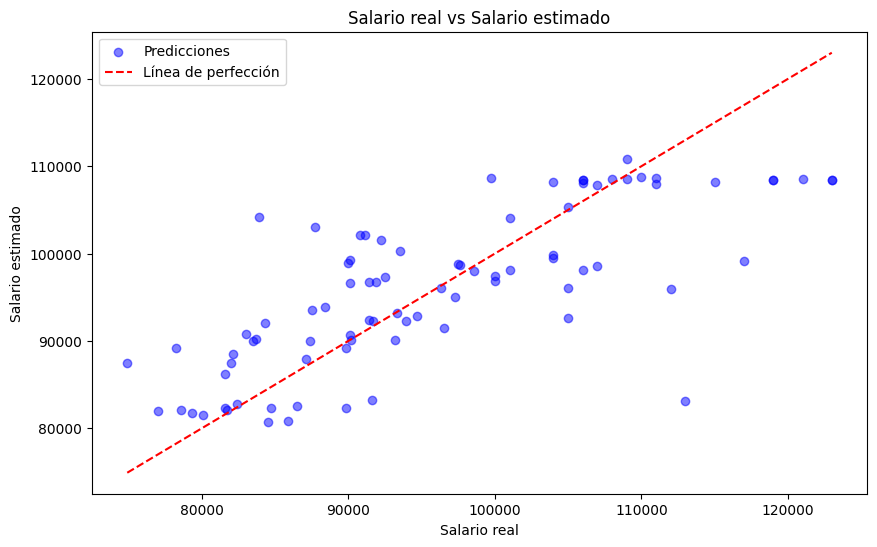

In [10]:
# Predicciones del modelo (salario estimado) sobre el mismo conjunto de datos
y_pred = model.predict(X)

# Valores reales vs predicciones; la línea roja marca la predicción perfecta (real = predicho)
plt.figure(figsize=(10, 6))
plt.scatter(y, y_pred, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')
plt.title('Salario real vs Salario estimado')
plt.xlabel('Salario real')
plt.ylabel('Salario estimado')
plt.legend()
plt.show()

**Discusión (salario real vs estimado):**

- En general los puntos siguen la línea de perfección: cuando el salario real es mayor, el estimado también lo es. Aun así, muchos puntos quedan lejos de la línea.
- Los salarios estimados solo van de unos 80,000 a 111,000, mientras que los reales van de 74,900 a 123,000. Por eso el modelo sobreestima los salarios más bajos (reales cercanos a 75,000–80,000 se estiman entre 82,000 y 89,000) y subestima los más altos (reales de 115,000 a 123,000 se estiman alrededor de 108,000).
- Varios puntos se alinean de forma horizontal cerca de 108,000 de estimado. Son universidades con costo y región parecidos que reciben casi la misma predicción, aunque sus salarios reales sean distintos.
- Hay un caso muy alejado: un salario real cercano a 113,000 que el modelo estima en unos 83,000.

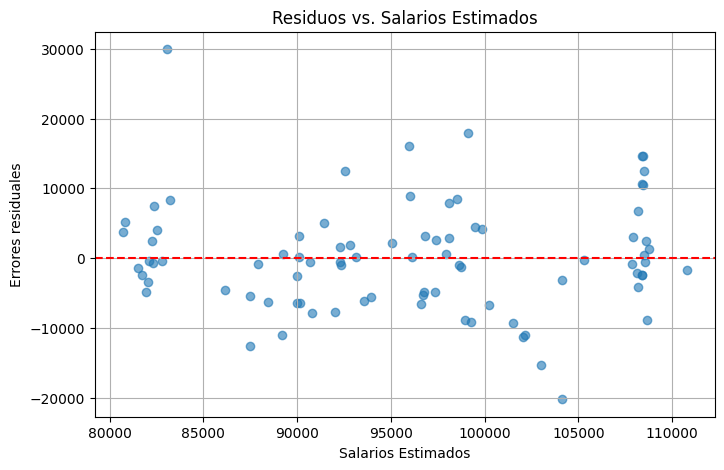

In [11]:
# Errores residuales: diferencia entre el salario real y el estimado
residuals = y - y_pred

# Residuos vs salarios estimados; la línea en 0 sirve de referencia para ver
# si los errores se reparten al azar por arriba y por abajo
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Salarios Estimados')
plt.ylabel('Errores residuales')
plt.title('Residuos vs. Salarios Estimados')
plt.grid(True)
plt.show()

**Discusión (errores residuales):**

- Los residuos quedan repartidos por arriba y por abajo de la línea en 0, y la mayoría está aproximadamente entre −12,000 y +15,000. No se ve una curva clara, lo que sugiere que una relación lineal es razonable.
- Los puntos forman bandas verticales. Las más marcadas están cerca de 81,000–83,000 y de 108,000–109,000 de salario estimado, y corresponden a grupos de universidades con costo y región similares.
- La dispersión no es igual en todo el rango. En la banda de 108,000–109,000 los errores van de unos −9,000 a +15,000, mientras que en la banda baja la mayoría va de unos −5,000 a +8,000. Es decir, el error parece crecer un poco en los salarios estimados más altos.
- Hay residuos grandes aislados. El mayor es de casi +30,000 (es el caso que se estimó en unos 83,000 en la gráfica anterior) y el menor es de unos −20,000 con un estimado cercano a 104,000.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

# Evaluación con el mismo conjunto de datos usado para ajustar el modelo (sin train/test)
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
r2 = r2_score(y, y_pred)             # Coeficiente de determinación
print('Evaluación del modelo:')
print(f'Error cuadrático medio (MSE): {mse:.2f}')
print(f'R² (R-squared): {r2:.4f}')

Evaluación del modelo:
Error cuadrático medio (MSE): 60480269.15
R² (R-squared): 0.5705


**Discusión de la evaluación:**

- **MSE = 60,480,269.15.** Es el promedio de los errores al cuadrado, en dólares al cuadrado, y por eso sale un número tan grande. No se puede leer directo en dólares, pero sirve para comparar contra otros modelos con los mismos datos: mientras menor, mejor.
- **R² = 0.5705.** El modelo con cost y location explica alrededor del 57.05% de la variación del salario. El 42.95% restante depende de factores que el modelo no incluye. Es un ajuste moderado, coherente con lo que se vio en los residuos: el modelo sigue la tendencia general, pero se equivoca bastante en varios casos.
- Estas métricas se calcularon con los mismos datos que se usaron para ajustar el modelo. Por eso miden qué tan bien se ajusta a esos datos y no qué tan bien predeciría universidades nuevas.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [13]:
import statsmodels.api as sm

# Análisis de componentes de varianza con MixedLM, siguiendo la página de statsmodels indicada.
# Forma elegida: la del diseño anidado de la página, con un intercepto aleatorio por grupo
# (re_formula="1", groups=...). Aquí solo hay un factor de agrupación (location), así que no
# hace falta un segundo nivel con vc_formula ni el diseño cruzado.
# - salary ~ cost: salary es la variable dependiente y cost entra como efecto fijo
# - groups="location": cada región es un grupo con su propio intercepto aleatorio
# - re_formula="1": el efecto aleatorio es solo el intercepto; su varianza ("location Var")
#   mide cuánto cambia el salario promedio entre regiones, y "Scale" es la varianza residual
model_vc = sm.MixedLM.from_formula(
    "salary ~ cost",
    re_formula="1",
    groups="location",
    data=df,
)
# fit() con los valores por defecto, como en la página (método REML)
result_vc = model_vc.fit()
print(result_vc.summary())


               Mixed Linear Model Regression Results
Model:                MixedLM   Dependent Variable:   salary       
No. Observations:     85        Method:               REML         
No. Groups:           4         Scale:                64259988.9170
Min. group size:      19        Log-Likelihood:       -883.7724    
Max. group size:      25        Converged:            Yes          
Mean group size:      21.2                                         
-------------------------------------------------------------------
                Coef.     Std.Err.   z    P>|z|   [0.025    0.975] 
-------------------------------------------------------------------
Intercept       86475.116 4755.851 18.183 0.000 77153.819 95796.412
cost                0.063    0.017  3.619 0.000     0.029     0.097
location Var 63375113.891 6902.606                                 



**Discusión del análisis de componentes de varianza:**

- El modelo usa las 85 universidades repartidas en 4 grupos (las regiones), con entre 19 y 25 universidades por grupo. El ajuste convergió ("Converged: Yes") con el método REML.
- **Efecto fijo de cost:** el coeficiente es 0.063 (p = 0.000, intervalo de 0.029 a 0.097). Si el costo sube 1 dólar, el salario estimado sube unos 0.063 dólares. La cifra es muy parecida al 0.0605 de la regresión de la sección 3, y como el intervalo no incluye el 0, el costo sí se relaciona con el salario.
- **Intercepto (86,475.116):** es el salario estimado de una región "promedio" con costo 0. Igual que en la sección 3, no tiene sentido práctico porque ninguna universidad cuesta 0.
- **Varianza del grupo location (location Var = 63,375,113.891):** mide cuánto cambia el salario promedio de una región a otra una vez que se toma en cuenta el costo. No es cercana a 0, así que la región sí aporta variación propia al salario. Esto coincide con la sección 3, donde las diferencias entre regiones eran de miles de dólares.
- **Varianza residual (Scale = 64,259,988.917):** es la variación del salario entre universidades de una misma región que el costo no explica.
- Las dos varianzas son casi del mismo tamaño (unos 63.4 y 64.3 millones). Es decir, después de considerar el costo, la variación del salario se reparte en partes parecidas entre las diferencias entre regiones y las diferencias entre universidades dentro de cada región.
- Hay que tomar con cautela la varianza de location, porque se estima a partir de solo 4 grupos.
- Respecto al problema planteado: el salario sí está relacionado con el costo de la educación, pero la localidad explica una parte importante de la variación del salario.